# Assessment 3: Data Cleaning and Univariate Analysis (CO2, BT4)
**School of Computer Science and Engineering** | BCSE331P - Exploratory Data Analysis | Fall Semester 2026-27

Dataset: **BEPS**. R packages dplyr / tidyr / ggplot2 / stringr / forcats -> Python **pandas / numpy / seaborn+matplotlib / str accessor / category dtype**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Import the dataset

In [2]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/BEPS.csv"
df = pd.read_csv(URL)

# BEPS has an unnamed row-index column -> drop it; replace '.' in names with '_' (easier in Python)
df = df.loc[:, ~df.columns.str.match(r"^(Unnamed.*|X|rownames)$")]
df.columns = df.columns.str.replace(".", "_", regex=False)
print("Shape:", df.shape)
df.head()

Shape: (1525, 10)


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male


## 2. First and last six records

In [3]:
display(df.head(6))
display(df.tail(6))

,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male
5,Labour,47,3,4,4,4,2,4,2,male


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
1519,Conservative,35,3,4,4,2,4,8,2,male
1520,Conservative,67,5,3,2,4,4,11,3,male
1521,Conservative,73,2,2,4,4,4,8,2,male
1522,Labour,37,3,3,5,4,4,2,2,male
1523,Conservative,61,3,3,1,4,1,11,2,male
1524,Conservative,74,2,3,2,4,4,11,0,female


## Preparing demo data for the cleaning tasks


In [4]:
rng = np.random.default_rng(42)
data = df.copy()
num_cols0 = data.select_dtypes(include="number").columns.tolist()
data[num_cols0] = data[num_cols0].astype(float)

for col in ["age", "economic_cond_national", "Blair", "Hague", "Europe", "vote", "gender"]:
    idx = rng.choice(data.index, size=int(0.05 * len(data)), replace=False)
    data.loc[idx, col] = np.nan

# extra column with ~80% missing values
data["survey_score"] = np.where(rng.random(len(data)) < 0.8, np.nan, rng.integers(1, 10, len(data)))

# 15 duplicated rows
data = pd.concat([data, data.sample(15, random_state=7)], ignore_index=True)
print(data.shape)

(1540, 11)


## 3. Total number of missing values

In [5]:
print("Total missing values:", data.isna().sum().sum())
data.isna().sum()

Total missing values: 1749


,0
vote,76
age,76
economic_cond_national,76
economic_cond_household,0
Blair,76
Hague,76
Kennedy,0
Europe,77
political_knowledge,0
gender,76


## 4. Records containing at least one missing value

In [6]:
na_rows = data[data.isna().any(axis=1)]
print("Rows with >=1 missing value:", len(na_rows))
na_rows.head(10)

Rows with >=1 missing value: 1302


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender,survey_score
0,Liberal Democrat,43.0,3.0,3.0,4.0,1.0,4.0,2.0,2.0,female,NaN
1,Labour,36.0,4.0,4.0,4.0,4.0,4.0,5.0,2.0,male,NaN
2,Labour,35.0,4.0,4.0,5.0,2.0,3.0,3.0,2.0,male,NaN
3,Labour,24.0,4.0,2.0,2.0,1.0,3.0,4.0,0.0,female,NaN
4,Labour,41.0,2.0,2.0,1.0,1.0,4.0,6.0,2.0,male,NaN
5,Labour,47.0,3.0,4.0,4.0,4.0,2.0,4.0,2.0,male,NaN
6,Liberal Democrat,57.0,2.0,2.0,4.0,4.0,2.0,11.0,2.0,male,NaN
7,NaN,77.0,3.0,4.0,4.0,1.0,4.0,1.0,0.0,male,NaN
8,Labour,39.0,3.0,3.0,4.0,4.0,4.0,11.0,0.0,female,NaN
9,Labour,70.0,3.0,2.0,5.0,NaN,1.0,11.0,2.0,male,NaN


## 5. Remove columns having more than 70% missing values

In [7]:
pct_missing = data.isna().mean() * 100
print(pct_missing.round(2))
cols_to_drop = pct_missing[pct_missing > 70].index.tolist()
print("\nDropping:", cols_to_drop)
data = data.drop(columns=cols_to_drop)
print("New shape:", data.shape)

vote                        4.94
age                         4.94
economic_cond_national      4.94
economic_cond_household     0.00
Blair                       4.94
Hague                       4.94
Kennedy                     0.00
Europe                      5.00
political_knowledge         0.00
gender                      4.94
survey_score               78.96
dtype: float64

Dropping: ['survey_score']
New shape: (1540, 10)


In [8]:
num_cols = data.select_dtypes(include="number").columns.tolist()
cat_cols = data.columns.difference(num_cols).tolist()
print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

Numerical  : ['age', 'economic_cond_national', 'economic_cond_household', 'Blair', 'Hague', 'Kennedy', 'Europe', 'political_knowledge']
Categorical: ['gender', 'vote']


## 6. Replace missing numerical values with the **mean**

In [9]:
data_mean = data.copy()
data_mean[num_cols] = data_mean[num_cols].fillna(data_mean[num_cols].mean())
print("Missing numerical values left:", data_mean[num_cols].isna().sum().sum())

Missing numerical values left: 0


## 7. Replace missing numerical values with the **median**

In [10]:
data_median = data.copy()
data_median[num_cols] = data_median[num_cols].fillna(data_median[num_cols].median())
print("Missing numerical values left:", data_median[num_cols].isna().sum().sum())

Missing numerical values left: 0


## 8. Replace missing categorical values with the **mode**


In [11]:
clean = data_median.copy()
for col in cat_cols:
    clean[col] = clean[col].fillna(clean[col].mode()[0])
print("Total missing values now:", clean.isna().sum().sum())

Total missing values now: 0


## 9. Identify duplicate rows

In [12]:
dup_mask = clean.duplicated()
print("Number of duplicate rows:", dup_mask.sum())
clean[dup_mask].head()

Number of duplicate rows: 15


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
1525,Conservative,70.0,3.0,2.0,4.0,4.0,2.0,11.0,0.0,female
1526,Labour,70.0,5.0,4.0,2.0,5.0,5.0,11.0,0.0,male
1527,Labour,44.0,4.0,4.0,4.0,2.0,4.0,5.0,2.0,male
1528,Labour,52.0,3.0,3.0,4.0,1.0,3.0,1.0,2.0,female
1529,Conservative,49.0,2.0,3.0,2.0,3.0,2.0,11.0,0.0,male


## 10. Remove duplicate rows

In [13]:
clean = clean.drop_duplicates().reset_index(drop=True)
print("Duplicates left:", clean.duplicated().sum(), "| Shape:", clean.shape)

Duplicates left: 0 | Shape: (1525, 10)


## 11. Identify columns stored with incorrect data types

In [14]:
print(clean.dtypes, "\n")

for col in clean.columns:
    if pd.api.types.is_numeric_dtype(clean[col]) and clean[col].nunique() <= 11:
        print(f"'{col}': numeric ({clean[col].dtype}) but only {clean[col].nunique()} distinct values "
              f"-> ordinal/categorical rating, better stored as category")

vote                        object
age                        float64
economic_cond_national     float64
economic_cond_household    float64
Blair                      float64
Hague                      float64
Kennedy                    float64
Europe                     float64
political_knowledge        float64
gender                      object
dtype: object 

'economic_cond_national': numeric (float64) but only 5 distinct values -> ordinal/categorical rating, better stored as category
'economic_cond_household': numeric (float64) but only 5 distinct values -> ordinal/categorical rating, better stored as category
'Blair': numeric (float64) but only 5 distinct values -> ordinal/categorical rating, better stored as category
'Hague': numeric (float64) but only 5 distinct values -> ordinal/categorical rating, better stored as category
'Kennedy': numeric (float64) but only 5 distinct values -> ordinal/categorical rating, better stored as category
'Europe': numeric (float64) but only 11 di

## 12. Convert character variables into factors (category)

In [15]:
for col in cat_cols:
    clean[col] = clean[col].astype("category")

# the 1-5 / 0-3 / 1-11 rating-scale columns can be ordered factors as well (optional)
clean["political_knowledge"] = pd.Categorical(clean["political_knowledge"].astype(int), ordered=True)
print(clean.dtypes)

vote                       category
age                         float64
economic_cond_national      float64
economic_cond_household     float64
Blair                       float64
Hague                       float64
Kennedy                     float64
Europe                      float64
political_knowledge        category
gender                     category
dtype: object


## 13. Convert text to lowercase / uppercase

In [16]:
vote_lower  = clean["vote"].astype(str).str.lower()
vote_upper  = clean["vote"].astype(str).str.upper()
gender_title = clean["gender"].astype(str).str.title()

display(pd.DataFrame({"original": clean["vote"].astype(str), "lower": vote_lower,
                      "UPPER": vote_upper, "gender_title": gender_title}).head())

clean["vote"] = vote_lower.astype("category")      # keep lowercase version

,original,lower,UPPER,gender_title
0,Liberal Democrat,liberal democrat,LIBERAL DEMOCRAT,Female
1,Labour,labour,LABOUR,Male
2,Labour,labour,LABOUR,Male
3,Labour,labour,LABOUR,Female
4,Labour,labour,LABOUR,Male


## 14. Detect outliers using boxplots

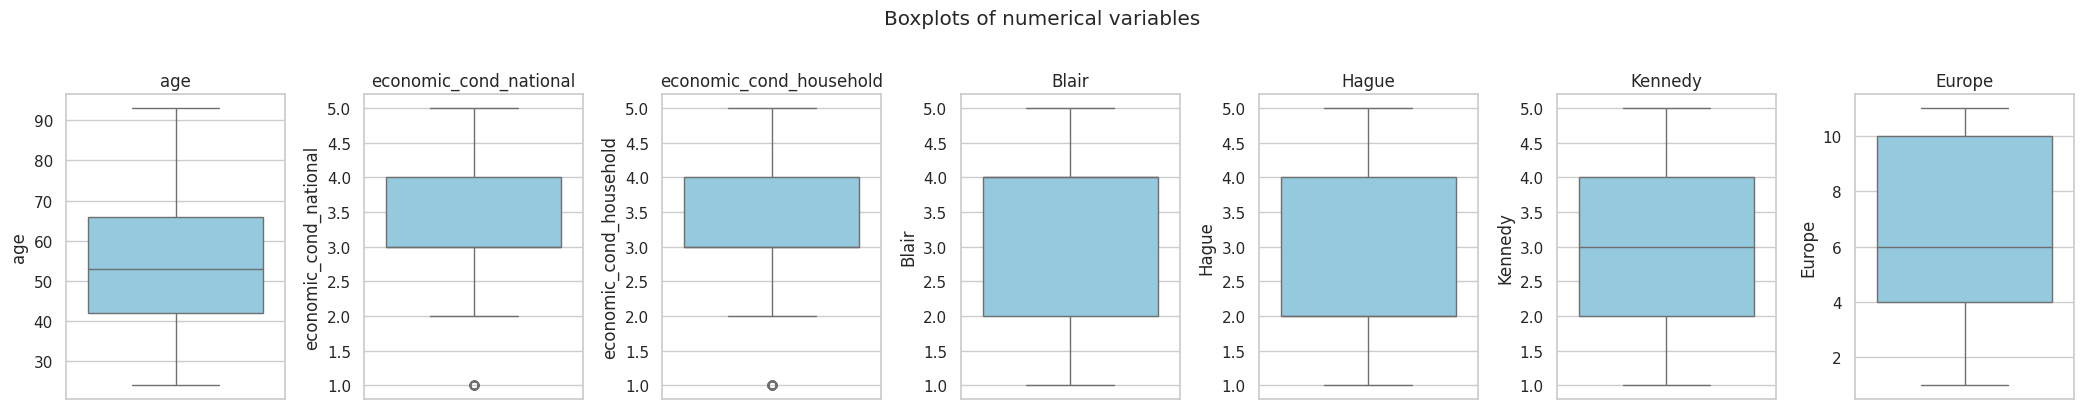

In [17]:
num_cols = clean.select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(1, len(num_cols), figsize=(3 * len(num_cols), 4))
for ax, col in zip(np.atleast_1d(axes), num_cols):
    sns.boxplot(y=clean[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.suptitle("Boxplots of numerical variables", y=1.02)
plt.tight_layout()
plt.show()

## 15. Outliers using the IQR method (Q1 - 1.5 IQR, Q3 + 1.5 IQR)

In [18]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in num_cols:
    lo, hi = iqr_bounds(clean[col])
    n_out = ((clean[col] < lo) | (clean[col] > hi)).sum()
    rows.append([col, round(lo, 2), round(hi, 2), n_out])
display(pd.DataFrame(rows, columns=["variable", "lower_fence", "upper_fence", "n_outliers"]))

,variable,lower_fence,upper_fence,n_outliers
0,age,6.0,102.0,0
1,economic_cond_national,1.5,5.5,35
2,economic_cond_household,1.5,5.5,65
3,Blair,-1.0,7.0,0
4,Hague,-1.0,7.0,0
5,Kennedy,-1.0,7.0,0
6,Europe,-5.0,19.0,0


## 16. Remove extreme outliers (beyond 3 x IQR) from the continuous variable `age`


In [19]:
lo, hi = iqr_bounds(clean["age"], k=3)
before = len(clean)
clean = clean[(clean["age"] >= lo) & (clean["age"] <= hi)].reset_index(drop=True)
print(f"Extreme-outlier fences: [{lo:.1f}, {hi:.1f}] | rows removed: {before - len(clean)} | shape: {clean.shape}")

Extreme-outlier fences: [-30.0, 138.0] | rows removed: 0 | shape: (1525, 10)


## 17. Histogram of a numerical variable and interpretation

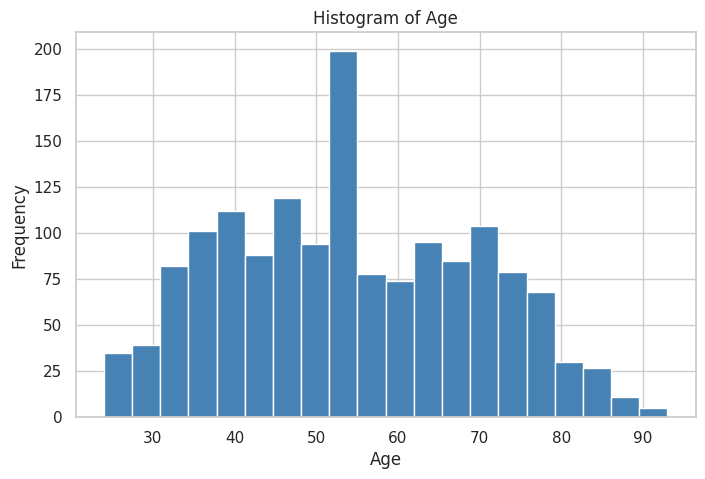

Mean = 54.14, Median = 53.00, Skewness = 0.154
Interpretation: the distribution of age is approximately symmetric.


In [20]:
fig, ax = plt.subplots()
ax.hist(clean["age"], bins=20, color="steelblue", edgecolor="white")
ax.set(title="Histogram of Age", xlabel="Age", ylabel="Frequency")
plt.show()

sk = clean["age"].skew()
shape = "right-skewed" if sk > 0.5 else "left-skewed" if sk < -0.5 else "approximately symmetric"
print(f"Mean = {clean['age'].mean():.2f}, Median = {clean['age'].median():.2f}, Skewness = {sk:.3f}")
print("Interpretation: the distribution of age is", shape + ".")

## 18. Add a density curve to the histogram

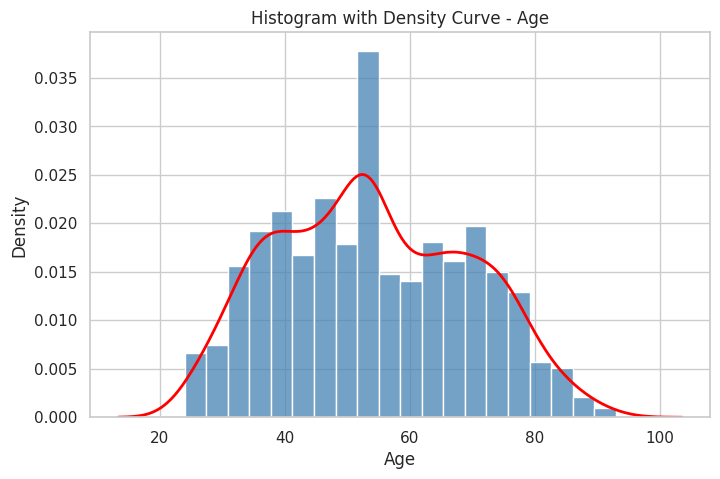

In [21]:
fig, ax = plt.subplots()
sns.histplot(clean["age"], bins=20, stat="density", color="steelblue", ax=ax)
sns.kdeplot(clean["age"], color="red", linewidth=2, ax=ax)
ax.set(title="Histogram with Density Curve - Age", xlabel="Age", ylabel="Density")
plt.show()

## 19. Violin plot

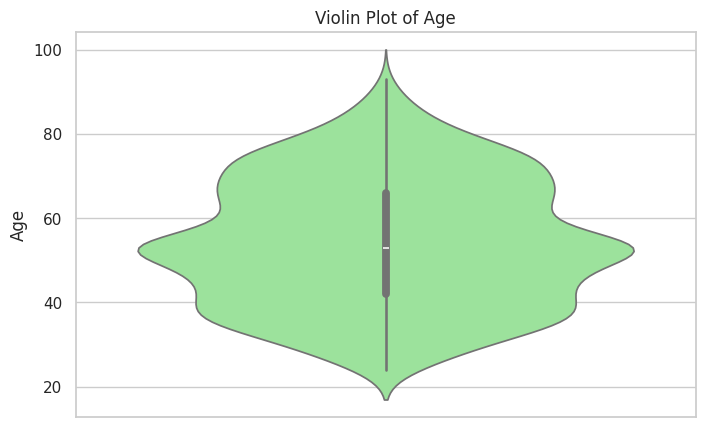

In [22]:
fig, ax = plt.subplots()
sns.violinplot(y=clean["age"], color="lightgreen", ax=ax)
ax.set(title="Violin Plot of Age", ylabel="Age")
plt.show()

## 20. Dot plot for a small numerical dataset

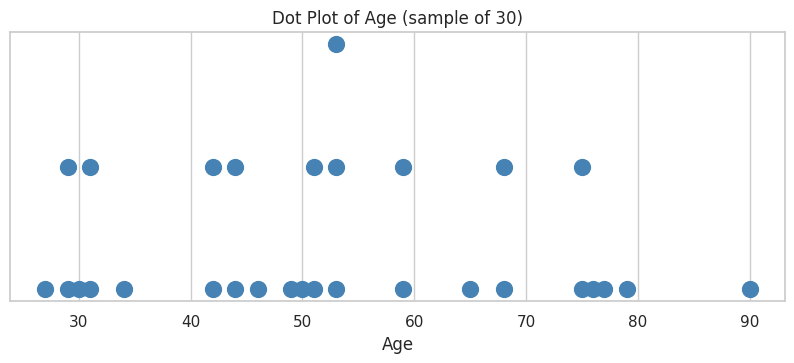

In [23]:
small = clean["age"].sample(30, random_state=1).round().astype(int)
counts = small.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.5))
for val, cnt in counts.items():
    ax.scatter([val] * cnt, range(1, cnt + 1), s=130, color="steelblue")
ax.set(title="Dot Plot of Age (sample of 30)", xlabel="Age", yticks=[])
plt.show()

## 21. Frequency table of a categorical variable

In [24]:
freq = clean["vote"].value_counts()
freq_table = freq.rename_axis("vote").reset_index(name="frequency")
freq_table

,vote,frequency
0,labour,753
1,conservative,443
2,liberal democrat,329


## 22. Proportion and percentage of each category

In [25]:
freq_table["proportion"] = (freq_table["frequency"] / freq_table["frequency"].sum()).round(4)
freq_table["percentage"] = (freq_table["proportion"] * 100).round(2)
freq_table

,vote,frequency,proportion,percentage
0,labour,753,0.4938,49.38
1,conservative,443,0.2905,29.05
2,liberal democrat,329,0.2157,21.57


## 23. Bar chart - frequency of each category

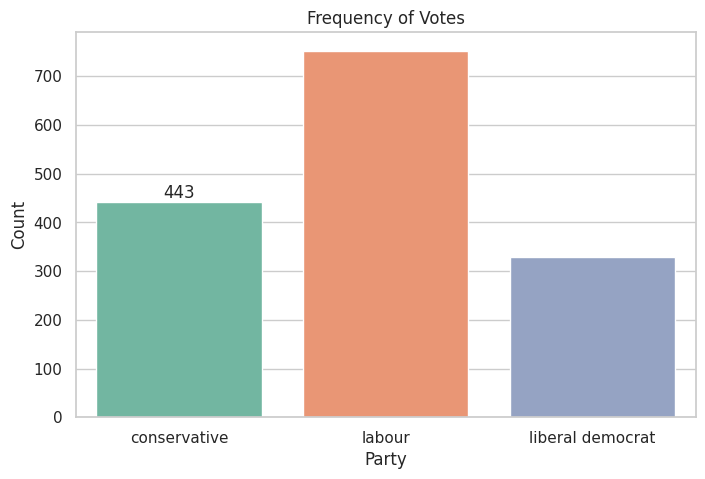

In [26]:
fig, ax = plt.subplots()
sns.barplot(x="vote", y="frequency", data=freq_table, palette="Set2", ax=ax)
ax.bar_label(ax.containers[0])
ax.set(title="Frequency of Votes", xlabel="Party", ylabel="Count")
plt.show()

## 24. Horizontal bar chart (variable with several categories: `Europe`, 11 levels)

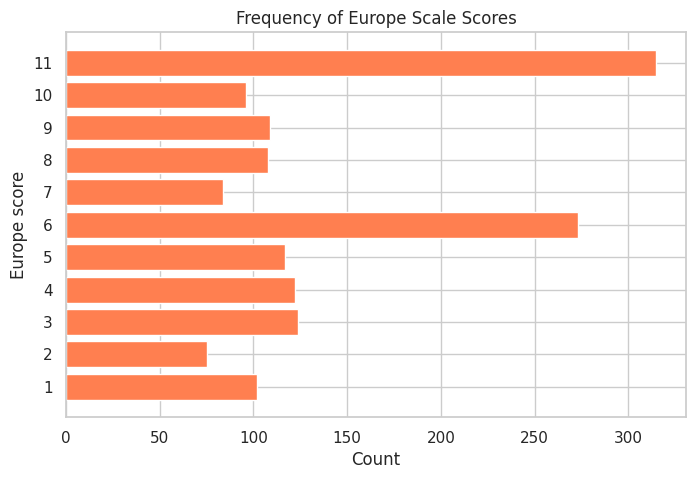

In [27]:
eur = clean["Europe"].astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(eur.index.astype(str), eur.values, color="coral")
ax.set(title="Frequency of Europe Scale Scores", xlabel="Count", ylabel="Europe score")
plt.show()

## 25. Percentage bar chart

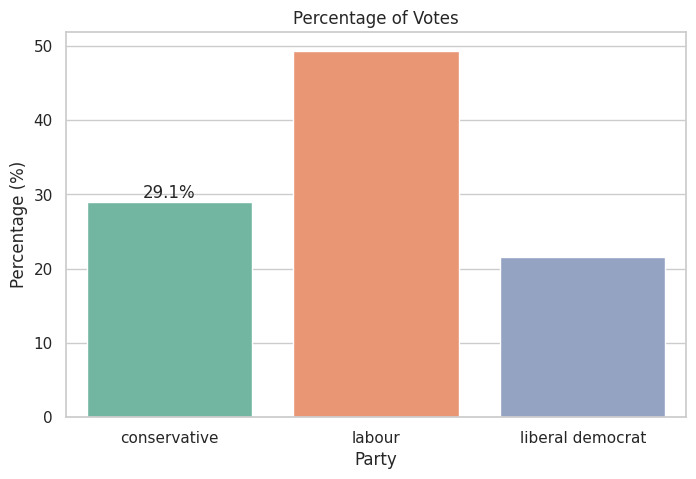

In [28]:
fig, ax = plt.subplots()
sns.barplot(x="vote", y="percentage", data=freq_table, palette="Set2", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set(title="Percentage of Votes", xlabel="Party", ylabel="Percentage (%)")
plt.show()

## 26. Pie chart

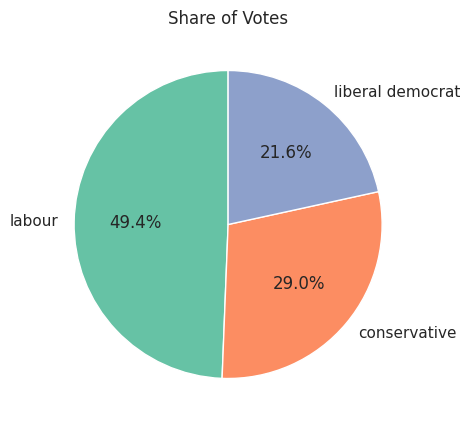

In [29]:
fig, ax = plt.subplots()
ax.pie(freq_table["frequency"], labels=freq_table["vote"], autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2"))
ax.set_title("Share of Votes")
plt.show()

## 27. Lollipop chart of categorical frequencies

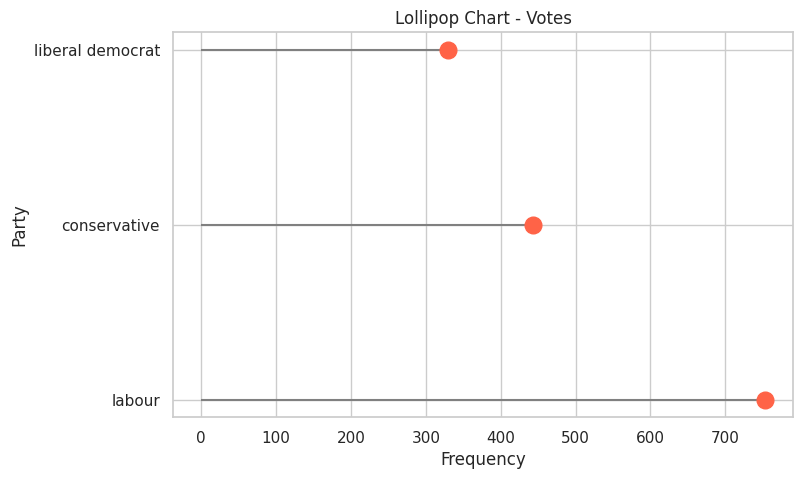

In [30]:
fig, ax = plt.subplots()
ax.hlines(y=freq_table["vote"], xmin=0, xmax=freq_table["frequency"], color="grey")
ax.plot(freq_table["frequency"], freq_table["vote"], "o", markersize=12, color="tomato")
ax.set(title="Lollipop Chart - Votes", xlabel="Frequency", ylabel="Party")
plt.show()

## 28. Dot chart (Cleveland dot plot)

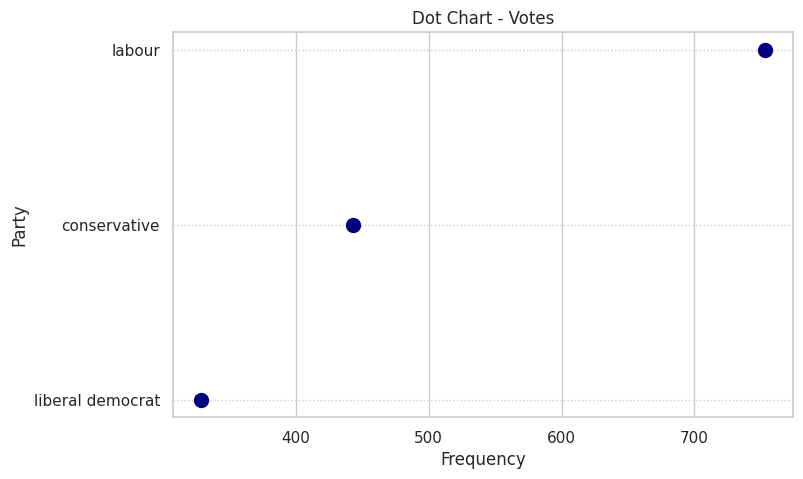

In [31]:
ordered = freq_table.sort_values("frequency")
fig, ax = plt.subplots()
ax.scatter(ordered["frequency"], ordered["vote"], s=100, color="navy")
ax.grid(axis="y", linestyle=":")
ax.set(title="Dot Chart - Votes", xlabel="Frequency", ylabel="Party")
plt.show()

## 29. Density plot (ggplot2 style) by group

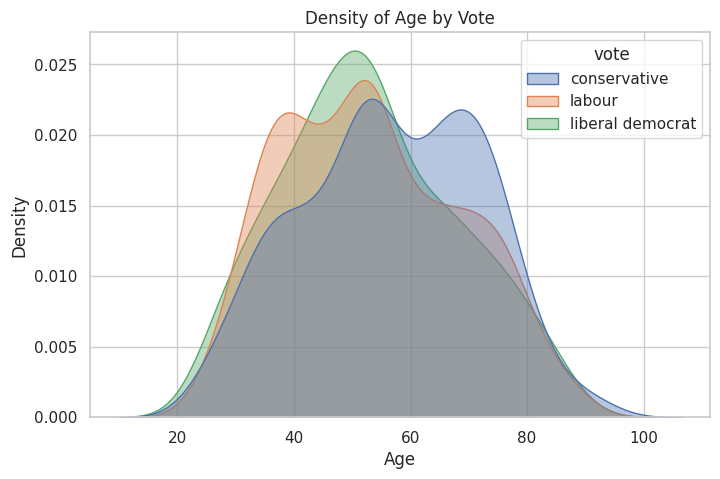

In [32]:
fig, ax = plt.subplots()
sns.kdeplot(data=clean, x="age", hue="vote", fill=True, alpha=0.4, common_norm=False, ax=ax)
ax.set(title="Density of Age by Vote", xlabel="Age", ylabel="Density")
plt.show()

## 30. `facet_wrap()` equivalent - distribution of age across groups

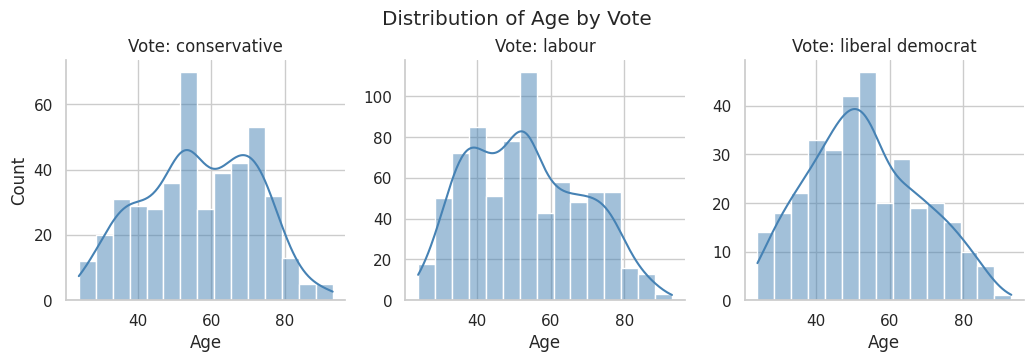

                  count   mean  median    std  skew
vote                                               
conservative        443  56.61    56.0  15.30 -0.10
labour              753  53.18    53.0  15.27  0.27
liberal democrat    329  53.02    53.0  15.01  0.24


In [33]:
g = sns.displot(data=clean, x="age", col="vote", col_wrap=3, kde=True, bins=15,
                height=3.5, color="steelblue", facet_kws={"sharey": False})
g.set_titles("Vote: {col_name}")
g.set_axis_labels("Age", "Count")
g.figure.suptitle("Distribution of Age by Vote", y=1.03)
plt.show()

print(clean.groupby("vote", observed=True)["age"].agg(["count", "mean", "median", "std", "skew"]).round(2))